# 📊 Exploratory Data Analysis (EDA) on Bank Marketing Dataset

## 📝 Introduction
- Analyze the Bank Marketing dataset to identify factors influencing term deposit subscriptions.
- Use visualizations and statistics to explain findings and guide business decisions.

---

## 🔍 Dataset Overview
- Data source: SQLite database (`bmarket.db`)
- Records: 41,188 entries.
- Features: Client demographics, loans, contact methods, campaign interactions, subscription status.
### 1. Load Data
- Connect to SQLite database and load the `bank_marketing` table into a DataFrame.
- View sample data to verify successful loading.


In [1]:
import sqlite3
import pandas as pd

# Connect to the database
conn = sqlite3.connect('data/bmarket.db')

# Show table names
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn)
print(tables)

             name
0  bank_marketing


In [2]:
# Load the data from the table
df = pd.read_sql("SELECT * FROM bank_marketing;", conn)

# View the first 5 rows
df.head()

,Client ID,Age,Occupation,Marital Status,Education Level,Credit Default,Housing Loan,Personal Loan,Contact Method,Campaign Calls,Previous Contact Days,Subscription Status
0,32885,57 years,technician,married,high.school,no,no,yes,Cell,1,999,no
1,3170,55 years,unknown,married,unknown,unknown,yes,no,telephone,2,999,no
2,32207,33 years,blue-collar,married,basic.9y,no,no,no,cellular,1,999,no
3,9404,36 years,admin.,married,high.school,no,no,no,Telephone,4,999,no
4,14021,27 years,housemaid,married,high.school,no,None,no,Cell,2,999,no


### 2. Data Overview & Missing Values Check
- Display data types and non-null counts to understand dataset structure.
- Identify missing values and 'unknown' entries in categorical columns for cleaning decisions.


In [3]:
# Data types, non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Client ID              41188 non-null  int64 
 1   Age                    41188 non-null  object
 2   Occupation             41188 non-null  object
 3   Marital Status         41188 non-null  object
 4   Education Level        41188 non-null  object
 5   Credit Default         41188 non-null  object
 6   Housing Loan           16399 non-null  object
 7   Personal Loan          37042 non-null  object
 8   Contact Method         41188 non-null  object
 9   Campaign Calls         41188 non-null  int64 
 10  Previous Contact Days  41188 non-null  int64 
 11  Subscription Status    41188 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.8+ MB


In [4]:
# Check for nulls
print(df.isnull().sum())

# Check for 'unknown' or 'None' strings in categorical columns
for col in df.columns:
    print(f"{col}: {df[col].isin(['unknown', 'None']).sum()} unknown entries")

Client ID                    0
Age                          0
Occupation                   0
Marital Status               0
Education Level              0
Credit Default               0
Housing Loan             24789
Personal Loan             4146
Contact Method               0
Campaign Calls               0
Previous Contact Days        0
Subscription Status          0
dtype: int64
Client ID: 0 unknown entries
Age: 0 unknown entries
Occupation: 330 unknown entries
Marital Status: 80 unknown entries
Education Level: 1731 unknown entries
Credit Default: 8597 unknown entries
Housing Loan: 393 unknown entries
Personal Loan: 877 unknown entries
Contact Method: 0 unknown entries
Campaign Calls: 0 unknown entries
Previous Contact Days: 0 unknown entries
Subscription Status: 0 unknown entries


### 3. Descriptive Statistics
- Summarize numerical and categorical variables to understand value distributions.
- Check the balance of the target variable (`Subscription Status`).

In [5]:
# Describe numerical columns
df.describe()

# Describe all object (categorical) columns
df.describe(include='object')

,Age,Occupation,Marital Status,Education Level,Credit Default,Housing Loan,Personal Loan,Contact Method,Subscription Status
count,41188,41188,41188,41188,41188,16399,37042,41188,41188
unique,77,12,4,8,3,3,3,4,2
top,150 years,admin.,married,university.degree,no,yes,no,Cell,no
freq,4197,10422,24928,12168,32588,8595,30532,13100,36548


In [6]:
# Value counts for target variable
df['Subscription Status'].value_counts(normalize=True)

Subscription Status
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

### 4. Age Distribution Analysis
- Visualize client age distribution to identify common age ranges and outliers.
- Understand potential age-related trends in subscription behavior.


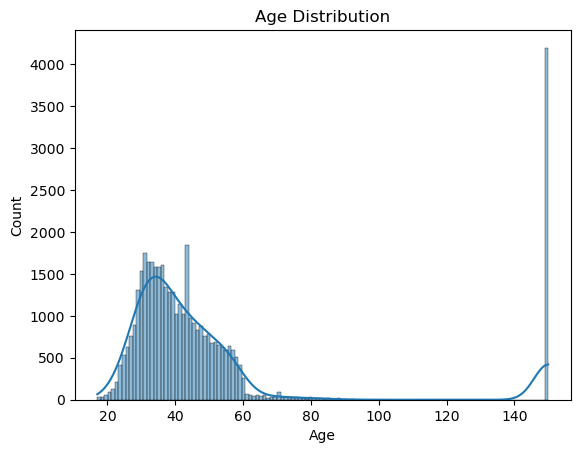

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Clean 'Age' column by removing 'years' and converting to float
# First check if the column Acontains strings, if so then extract numbers
if df['Age'].dtype == 'object':
    df['Age'] = df['Age'].str.extract(r'(\d+)').astype(float)
else:
    # If it's already numeric, just ensure it's float type
    df['Age'] = df['Age'].astype(float)

# Plot age distribution
sns.histplot(df['Age'], kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.show()  # Fixed typo: plshow() -> plt.show()

### Age Distribution (Insights)
- Most clients fall between the ages of 25 to 60.
- There are a few outliers, including clients aged 90+.
- The distribution is slightly right-skewed, indicating more younger clients.

### 5. Subscription by Marital Status
- Analyze how marital status affects subscription likelihood.
- Compare subscription rates across married, single, divorced clients.


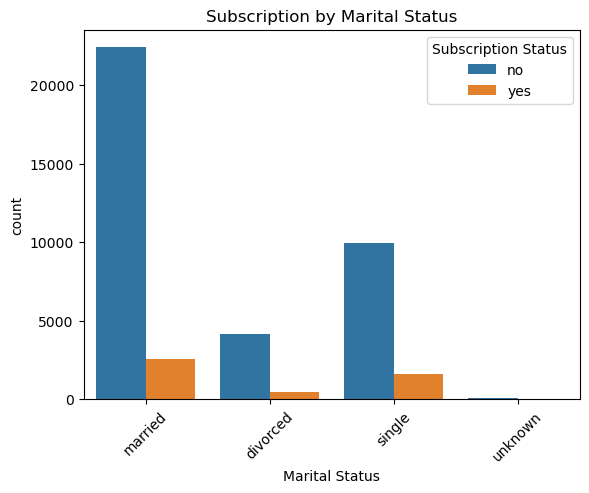

In [8]:
sns.countplot(data=df, x='Marital Status', hue='Subscription Status')
plt.title('Subscription by Marital Status')
plt.xticks(rotation=45)
plt.show()

### Subscription by Marital Status (Insights)
- Married clients form the majority of the dataset.
- Single clients show a slightly higher subscription rate compared to others.
- Divorced clients also show moderate subscription interest.

### 6. Subscription by Education Level
- Investigate the impact of education level on subscription decisions.
- Identify patterns between educational attainment and subscription rates.

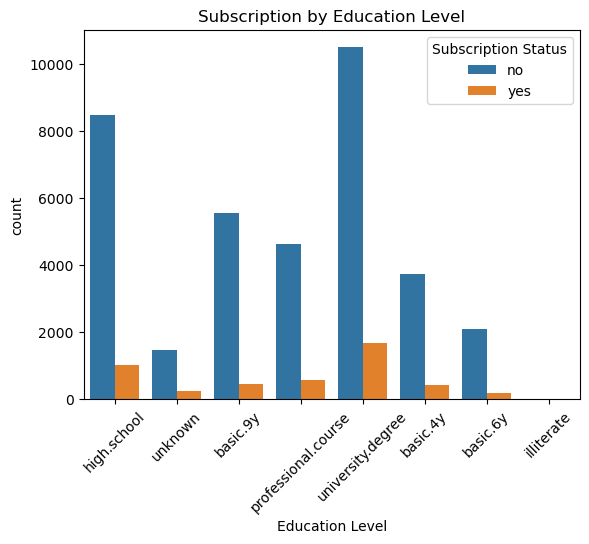

In [8]:
sns.countplot(data=df, x='Education Level', hue='Subscription Status')
plt.title('Subscription by Education Level')
plt.xticks(rotation=45)
plt.show()

### Subscription by Education Level (Insights)
- Clients with a university degree have the highest proportion of term deposit subscriptions.
- Those with basic education (e.g., 'basic.9y') have the lowest subscription rates.
- This suggests education may be a factor in client financial decision-making.

### 7. Subscription vs Housing Loan
- Analyze the relationship between housing loan ownership and subscription likelihood.
- Financial commitments like loans may influence decision-making.


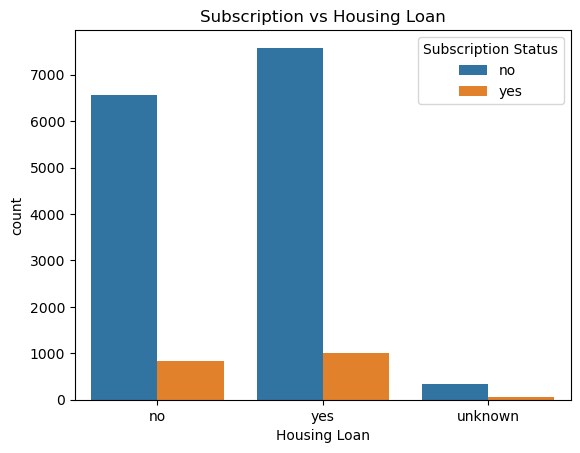

In [10]:
sns.countplot(data=df, x='Housing Loan', hue='Subscription Status')
plt.title('Subscription vs Housing Loan')
plt.show()

### Subscription vs Housing Loan (Insights)
- Clients without a housing loan are more likely to subscribe to a term deposit.
- This may indicate that clients not burdened by housing loans are more financially flexible.


### 8. Subscription vs Personal Loan
- Examine the effect of personal loan obligations on subscription behavior.
- Assess how financial flexibility affects term deposit subscriptions.

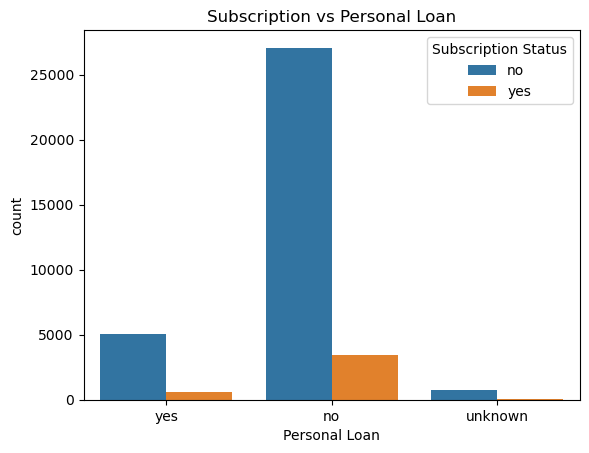

In [11]:
sns.countplot(data=df, x='Personal Loan', hue='Subscription Status')
plt.title('Subscription vs Personal Loan')
plt.show()

### Subscription vs Personal Loan (Insights)
- Clients without personal loans show higher subscription rates.
- Financial obligations like loans impact client decision-making.

### 9. Subscription vs Contact Method
- Analyze how the method of contact (e.g., phone, cellular) influences subscription conversion.
- Helps identify the most effective communication channels.

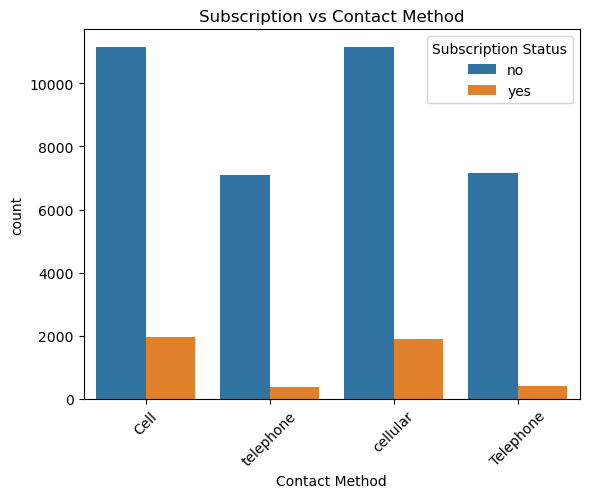

In [12]:
sns.countplot(data=df, x='Contact Method', hue='Subscription Status')
plt.title('Subscription vs Contact Method')
plt.xticks(rotation=45)
plt.show()


### Subscription vs Contact Method (Insights)
- 'Cell' and 'cellular' contacts have higher subscription conversion.
- Traditional telephone methods are less effective.

### 10. Subscription by Occupation
- Analyze how different occupations influence subscription behavior.
- Identify occupations with higher or lower subscription conversion.

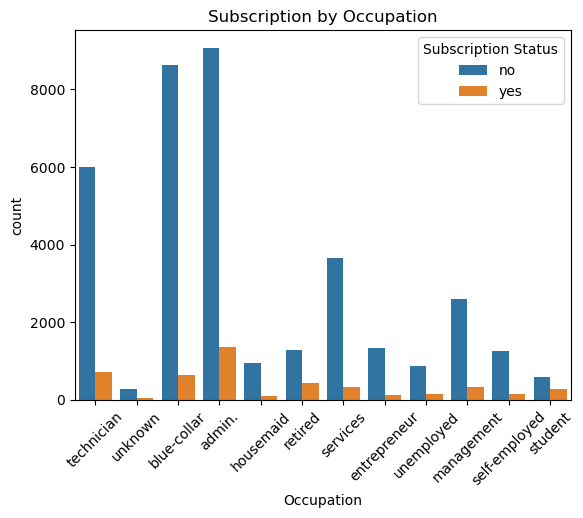

In [16]:
sns.countplot(data=df, x='Occupation', hue='Subscription Status')
plt.title('Subscription by Occupation')
plt.xticks(rotation=45)
plt.show()


### Subscription by occupation (Insights)
- Admin and blue-collar dominate the client base but have lower subscription rates.
- Retired and technicians show higher subscription rates relative to their population.
- Occupation influences subscription; focus on high-potential groups like retired and technicians.

### 11. Subscription by Credit Default
- Analyze the impact of credit default history on subscription rates.
- Identify risk factors affecting client subscription decisions.

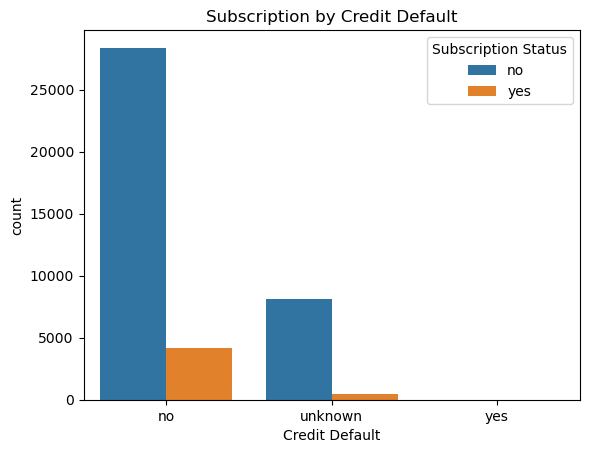

In [17]:
sns.countplot(data=df, x='Credit Default', hue='Subscription Status')
plt.title('Subscription by Credit Default')
plt.show()

### Subscription by Credit Default (Insights)
- Clients with no credit default have higher subscription rates.
- Clients with credit defaults rarely subscribe.
- 'Unknown' entries show lower subscription rates.

### 12. Correlation Matrix
- Analyze correlations among numerical features.
- Identify variables that might influence subscription likelihood.

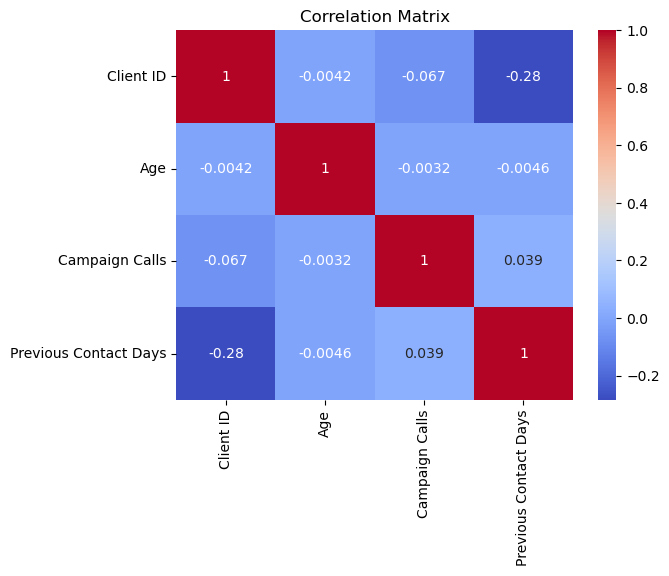

In [18]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


### Correlation Matrix (Insights)
- Weak correlations among numerical features.
- Slight negative correlation between Previous Contact Days and Subscription.
- No strong predictive single variable; multivariate models are needed.

### 12. Correlation Matrix
- Visualize age spread within subscription groups.
- Analyze if age impacts subscription likelihood.

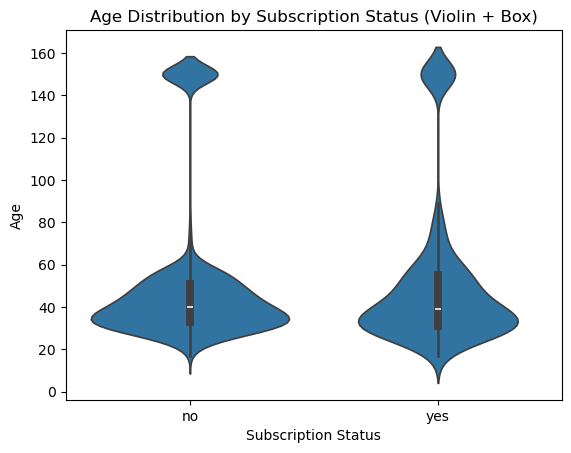

In [25]:
sns.violinplot(data=df, x='Subscription Status', y='Age', inner='box')
plt.title('Age Distribution by Subscription Status (Violin + Box)')
plt.show()

### Age Distribution by Subscription Status (Insights)
- Median ages are similar for both subscription groups.
- Subscribed clients show more spread in older age groups.
- Younger clients have slightly higher subscription density.

# Conclusion
- Factors influencing subscriptions: Education, Occupation, Loan Status, Contact Method, Age.
- Clients with financial burdens (loans, defaults) are less likely to subscribe.
- Contact method effectiveness suggests optimizing outreach via mobile.
- Multivariate predictive models are needed due to weak individual feature correlation.
